In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn, Tensor
from torch.utils.data import DataLoader, TensorDataset
import rasterio
from typing import NamedTuple

from constants import SEED, DEFAULT_TILE_SIZE
from grad_descent_train_eval import ExperimentRunner

np.random.seed(SEED)
torch.manual_seed(SEED)

# render figures as crisp vector graphics
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device.")

Using cuda device.


In [2]:
class FireLinearParams(NamedTuple):
    embed_dim: int
    num_categories: int = 1

    def __str__(self):
        return f"Lin(d={self.embed_dim}, out={self.num_categories})"


class FireLinear(nn.Module):
    def __init__(self, args: FireLinearParams):
        super().__init__()
        self.args = args
        self.net = nn.Linear(args.embed_dim, args.num_categories)

    def forward(self, X: Tensor):
        """
        Input: (batch, embed_dim, tile_rows, tile_cols)
        Output: (batch, num_categories, tile_rows, tile_cols)

        NOTE: nn.CrossEntropyLoss expects logits to be the second dimension.
        """
        X = X.permute(0, 2, 3, 1)
        logits = self.net(X)
        return logits.permute(0, 3, 1, 2)


In [3]:
DEFAULT_BATCH_SIZE = 256

def to_data_loader(
        X: np.ndarray,
        y: np.ndarray,
        shuffle: bool = False,
        batch_size: int = DEFAULT_BATCH_SIZE
    ) -> DataLoader:
    # nn.CrossEntropyLoss expects longs.
    dataset = TensorDataset(torch.Tensor(X), torch.Tensor(y).long())
    return DataLoader(dataset, shuffle=shuffle, batch_size=batch_size)

def load_surface_fuel_data(
        tile_size=DEFAULT_TILE_SIZE
) -> tuple[dict[int, int], np.ndarray, np.ndarray, DataLoader, DataLoader, DataLoader]:
    """
    Returns:
    - idx_to_class: Dictionary mapping a target label index back to its
      original numeric value.
    - X_tiles: (total_tiles, bands, tile_rows, tile_cols)
    - y_tiles: (total_tiles, tile_size, tile_size)
    - Each split feature matrix has shape:
        (num_tiles_in_split, bands, tile_rows, tile_cols)
    - And target matrix:
        (num_tiles_in_split, tile_rows, tile_cols)

    Each target_matrix contains indices of surface fuels. E.g., a value of 0
    corresponds to surface fuel code 99, which is "bare ground". This mapping
    is done because nn.CrossEntropyLoss expects values in the range [0, num_categories).
    """
    with rasterio.open("../../data/2022_foco_bbox_quant.tif") as src:
        X = src.read()
    with rasterio.open("../../data/surface_fuels_aligned.tif") as src:
        y_orig = src.read().squeeze()

    classes, y = np.unique(y_orig, return_inverse=True)
    idx_to_class = dict(enumerate(classes))
    assert y.shape == y_orig.shape

    # Select AOI that is evenly divisible by tile dimension.
    bands, rows, cols = X.shape
    n_rows = rows // tile_size
    n_cols = cols // tile_size
    X_cropped = X[:, :n_rows * tile_size, :n_cols * tile_size]
    y_cropped = y[:n_rows * tile_size, :n_cols * tile_size]

    X_tiles = X_cropped.reshape(bands, n_rows, tile_size, n_cols, tile_size)
    X_tiles = X_tiles.transpose(1, 3, 0, 2, 4).reshape(-1, bands, tile_size, tile_size)
    y_tiles = y_cropped.reshape(n_rows, tile_size, n_cols, tile_size)
    y_tiles = y_tiles.transpose(0, 2, 1, 3).reshape(-1, tile_size, tile_size)

    PATTERN = np.array([[1, 1, 1],
                        [1, 2, 3]], dtype="uint8")

    tile_r = np.arange(n_rows)[:, None] % PATTERN.shape[0]
    tile_c = np.arange(n_cols)[None, :] % PATTERN.shape[1]
    tile_split = PATTERN[tile_r, tile_c].ravel()  # (total_tiles,)

    train = to_data_loader(X_tiles[tile_split == 1], y_tiles[tile_split == 1], shuffle=True)
    val = to_data_loader(X_tiles[tile_split == 2], y_tiles[tile_split == 2])
    test = to_data_loader(X_tiles[tile_split == 3], y_tiles[tile_split == 3])

    return idx_to_class, X_tiles, y_tiles, train, val, test

In [4]:
idx_to_surface_fuel_cat, X, y, full_train_loader, full_val_loader, full_test_loader = load_surface_fuel_data()
X.shape, y.shape

((6348, 128, 64, 64), (6348, 64, 64))

In [5]:
batch_X, batch_y = next(iter(full_train_loader))
batch_X.shape, batch_y.shape

(torch.Size([256, 128, 64, 64]), torch.Size([256, 64, 64]))

In [6]:
num_surface_fuel_labels = len(np.unique(y))
print("Number of surface fuel categories in AOI =", num_surface_fuel_labels)

Number of surface fuel categories in AOI = 30


Running experiment: Lin(d=128, out=30)
epoch  1  train loss 29.265  val loss 20.694  (3s)
epoch  2  train loss 18.803  val loss 16.489  (2s)
epoch  3  train loss 15.515  val loss 14.030  (2s)
epoch  4  train loss 13.416  val loss 12.375  (2s)
epoch  5  train loss 12.009  val loss 11.256  (2s)
epoch  6  train loss 11.017  val loss 10.442  (2s)
epoch  7  train loss 10.269  val loss 9.783  (2s)
epoch  8  train loss 9.666  val loss 9.262  (2s)
epoch  9  train loss 9.170  val loss 8.819  (2s)
epoch 10  train loss 8.752  val loss 8.451  (2s)
epoch 11  train loss 8.393  val loss 8.121  (2s)
epoch 12  train loss 8.086  val loss 7.847  (2s)
epoch 13  train loss 7.812  val loss 7.591  (2s)
epoch 14  train loss 7.571  val loss 7.368  (2s)
epoch 15  train loss 7.354  val loss 7.167  (2s)
epoch 16  train loss 7.153  val loss 6.983  (2s)
epoch 17  train loss 6.970  val loss 6.814  (2s)
epoch 18  train loss 6.797  val loss 6.648  (2s)
epoch 19  train loss 6.639  val loss 6.500  (2s)
epoch 20  train l

,Classifier,Loss (val),Epochs,Param count
0,"Lin(d=128, out=30)",2.9897,120,3870


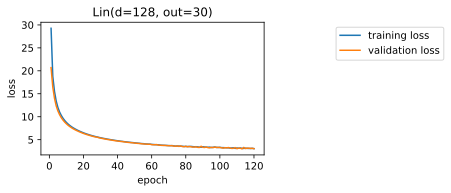

In [7]:
runner1_1 = (
    ExperimentRunner(FireLinear)
        .with_lr(0.0001)
        .with_patience(10)
        .with_epochs(120)
        .with_data(full_train_loader, full_val_loader)
        .add_experiments(
            FireLinearParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
            )
        ).with_plots()
)

runner_results1_1 = runner1_1.run(verbosity=1)
runner_results1_1

In [8]:
idx_to_fuel_code_lookup = torch.zeros(max(idx_to_surface_fuel_cat.keys()) + 1, dtype=torch.long, device=device)
for k, v in idx_to_surface_fuel_cat.items():
    idx_to_fuel_code_lookup[k] = v

In [9]:
# Render one tile prediction.
model = runner1_1.experiment_results[0].model.to(device)
val_sample_X, val_sample_y = next(iter(full_val_loader))
val_sample_X, val_sample_y = val_sample_X[:1].to(device), val_sample_y[:1].to(device)

with torch.no_grad():
    predicted_tile = model(val_sample_X).argmax(dim=1)

In [10]:
predicted_tile.shape

torch.Size([1, 64, 64])

In [11]:
predicted_surface_fuel_codes = idx_to_fuel_code_lookup[predicted_tile]
true_surface_fuel_codes = idx_to_fuel_code_lookup[val_sample_y]

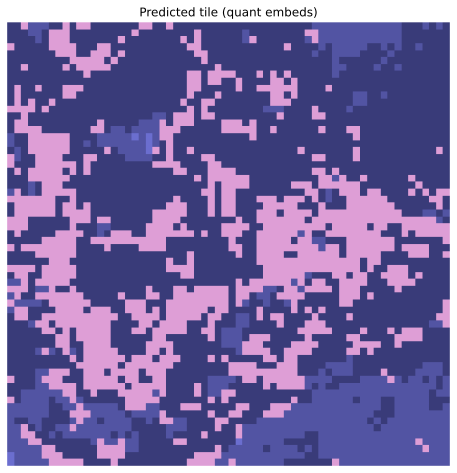

In [14]:
plt.figure(figsize=(10, 8))
plt.imshow(predicted_surface_fuel_codes.squeeze().cpu(), cmap="tab20b")
plt.title("Predicted tile (quant embeds)")
plt.axis("off")
plt.show();

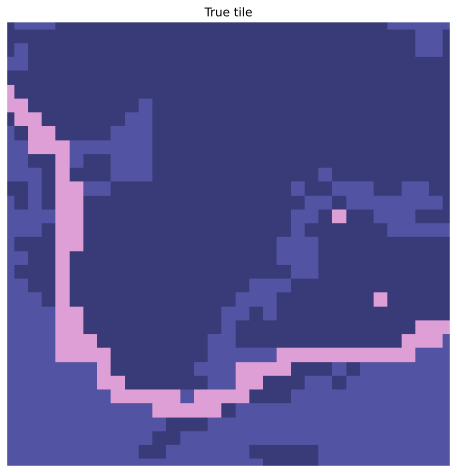

In [13]:
plt.figure(figsize=(10, 8))
plt.imshow(true_surface_fuel_codes.squeeze().cpu(), cmap="tab20b")
plt.title("True tile")
plt.axis("off")
plt.show();